<a href="https://colab.research.google.com/github/ballushe4ka/homeworkMLSUNC/blob/main/HW.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Кластеризация ЕГЭ (8.5 если сделаны все задачи)

Рядом лежат экселевские таблицы с координатами точек. В 3 и 4 задаче используется манхетеское расстояние. В остальных Евклидово.

* Постройте Распределение точек
* Кластеризуйте руками
* Постройте Распределение точек, отметьте принадлежность кластеров цветами
* Найдите среди в каждом кластере точку расстояние от которой до всех остальных минимально
* Выведите усреднение центров всех кластеров * 1000

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# Кластеризация (0.75 за каждый алгоритм на всех данных)

На предложенных распределениях данных проверьте предложенные алгоритмы. Постройте графики кластеризации для каждой пары алгоритм-данные, разные кластеры покрасьте разным цветом. Воспользуйтесь sklearn реализациями. Параметры кластеризации для разных алгоритмов подберите такие, чтобы алгоритмы можно было сравнивать (по возможности одинаковое количество кластеров и т.д.)

In [5]:
import time
import warnings
from itertools import cycle, islice
import numpy as np
import matplotlib.pyplot as plt
from sklearn import cluster, datasets as sk_datasets, mixture
from sklearn.neighbors import kneighbors_graph
from sklearn.preprocessing import StandardScaler
np.random.seed(0)

0.xls 1041 6671
1.xls 8177 738
2.xlsx 23130 635
3.xlsx 3078 -4758
4.xlsx 2588 4996
5.xlsx 61 3723


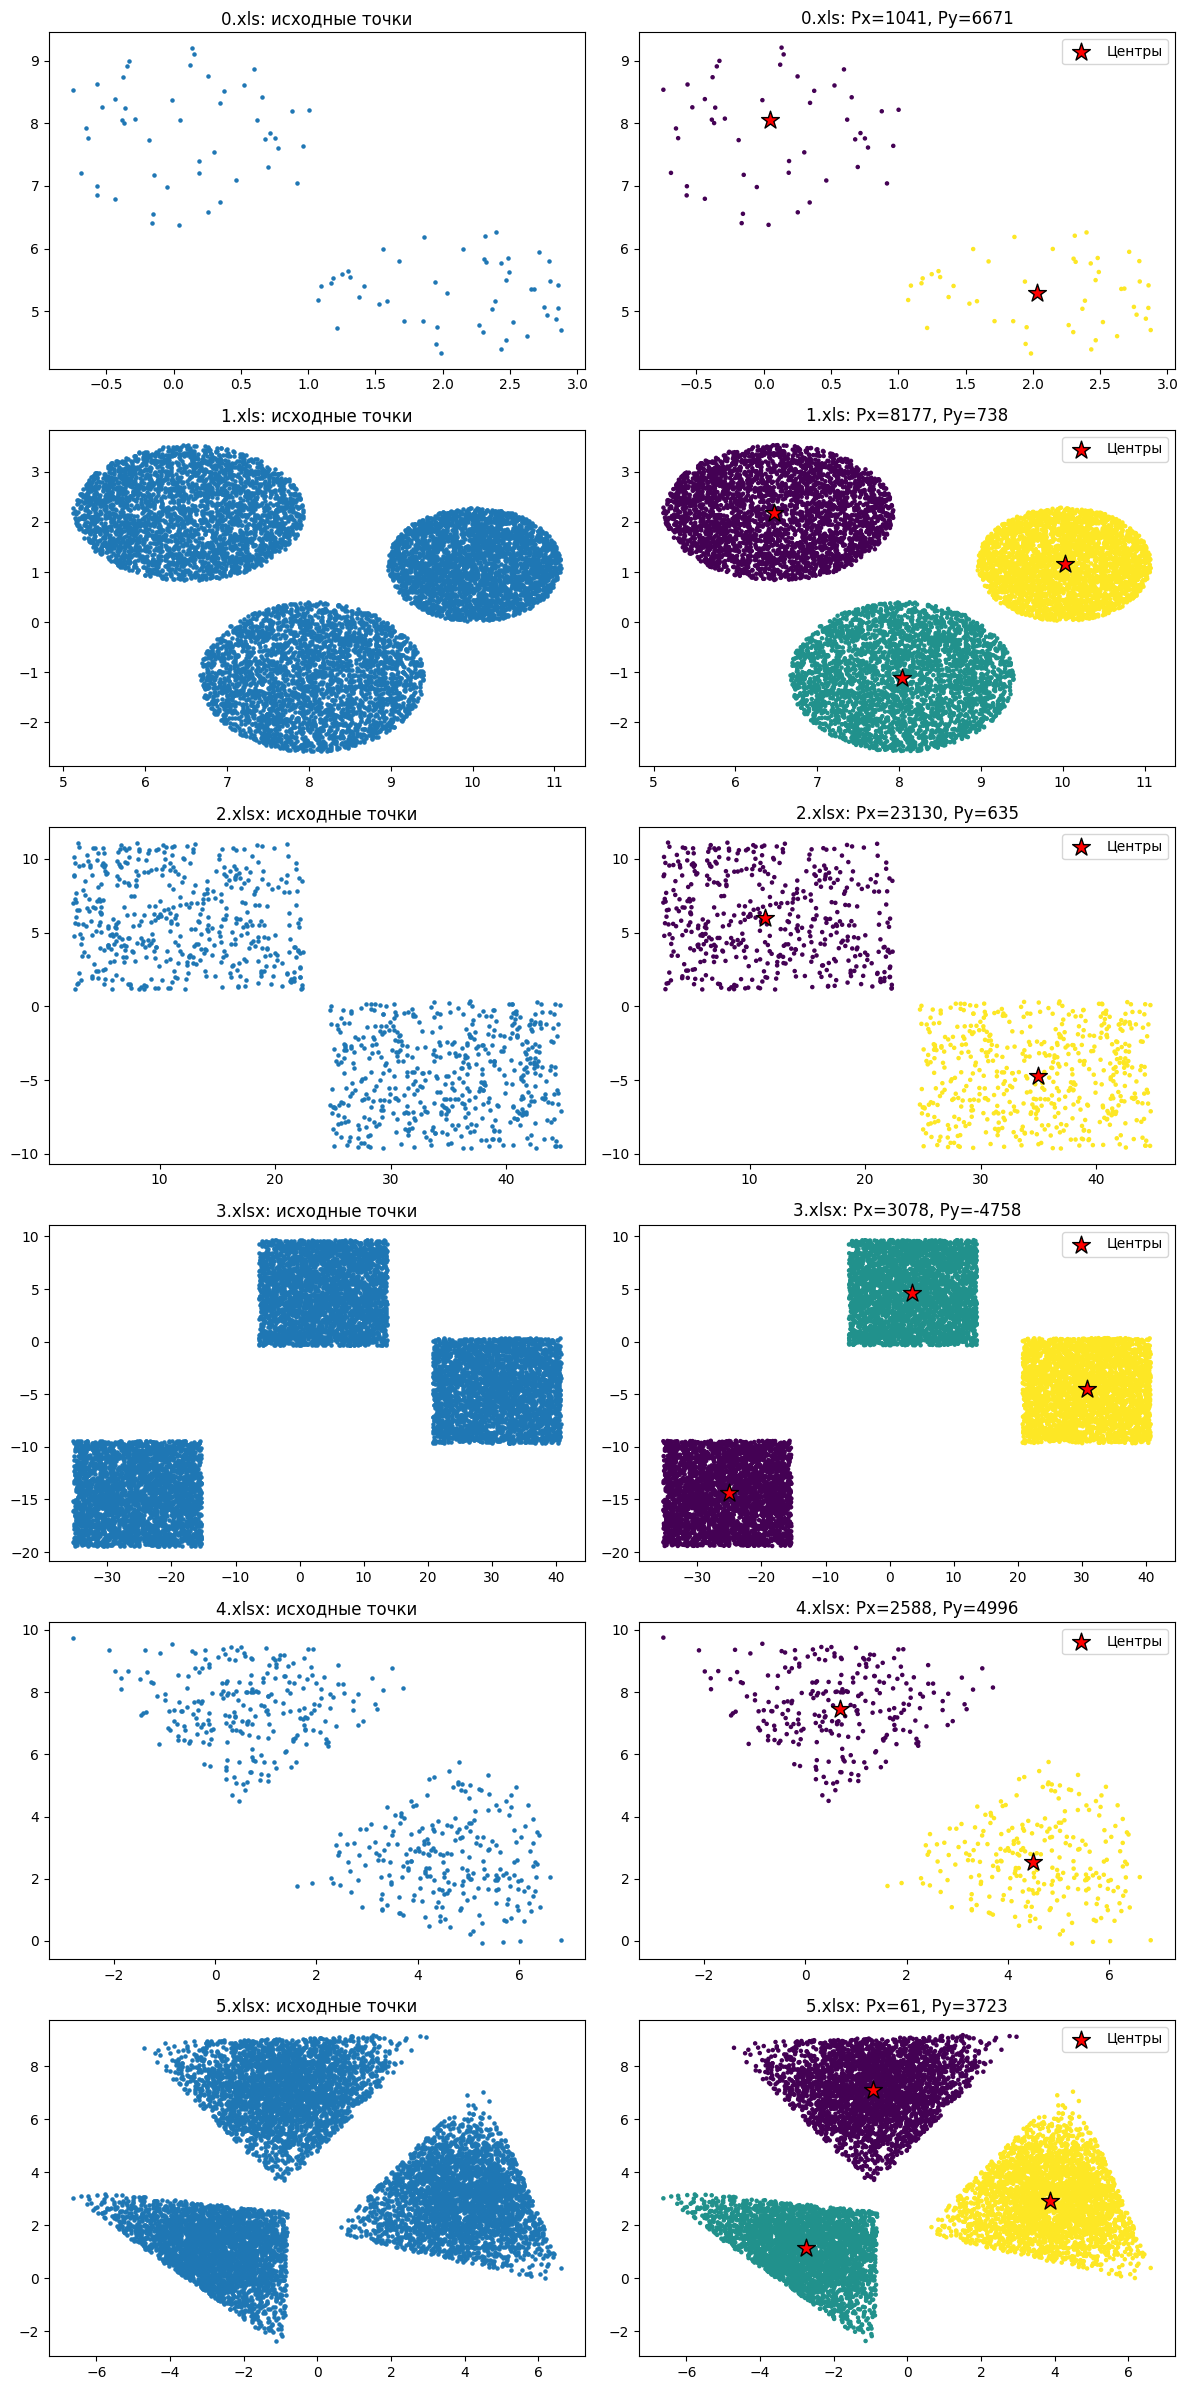

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
files = ['0.xls', '1.xls', '2.xlsx', '3.xlsx', '4.xlsx', '5.xlsx']
fig, axes = plt.subplots(6, 2, figsize=(12, 24))
for i, f in enumerate(files):
    if f in ['2.xlsx', '3.xlsx']:
        df = pd.read_excel(f, header=None, names=['X', 'Y'])
    else:
        df = pd.read_excel(f)
    X = df['X'].values
    Y = df['Y'].values
    if f == '0.xls':
        labels = np.where(Y > 6.3, 0, 1)
    elif f == '1.xls':
        labels = np.select([(X < 8.5) & (Y > 0.6), (X > 8.8) & (Y > -X + 9.0)], [0, 2], default=1)
    elif f == '2.xlsx':
        labels = np.where(X < 24, 0, 1)
    elif f == '3.xlsx':
        labels = np.select([X < -10, X < 18], [0, 1], default=2)
    elif f == '4.xlsx':
        labels = np.where(Y > X + 1.5, 0, 1)
    elif f == '5.xlsx':
        labels = np.select([(X < 0) & (Y < 3.5), Y > X + 3.0], [1, 0], default=2)
    centers = []
    for k in np.unique(labels):
        pts = df[labels == k][['X', 'Y']].values
        dx = pts[:, 0:1] - pts[:, 0]
        dy = pts[:, 1:2] - pts[:, 1]
        if f in ['3.xlsx', '4.xlsx']:
            dists = np.abs(dx) + np.abs(dy)
        else:
            dists = np.sqrt(dx**2 + dy**2)
        best_idx = np.argmin(dists.sum(axis=1))
        centers.append(pts[best_idx])
    centers = np.array(centers)
    ans = np.mean(centers, axis=0) * 1000
    axes[i, 0].scatter(X, Y, s=5)
    axes[i, 0].set_title(f"{f}: исходные точки")
    axes[i, 1].scatter(X, Y, c=labels, s=5)
    axes[i, 1].scatter(centers[:, 0], centers[:, 1], c='red', marker='*', s=180, edgecolors='black', label='Центры')
    axes[i, 1].set_title(f"{f}: Px={int(ans[0])}, Py={int(ans[1])}")
    axes[i, 1].legend()
    print(f, int(ans[0]), int(ans[1]))
plt.tight_layout()
plt.show()